# Decision Tree: Effect of Tree Depth and Splitting Criterion

**Aim:** To study how `max_depth` and the splitting criterion (`gini` vs `entropy`) affect the accuracy of a decision tree, and to observe overfitting and underfitting.

**Dataset:** Breast Cancer dataset from scikit-learn (569 samples, 30 features, 2 classes).

## 1. Import libraries and load data

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree

sns.set_theme(style="whitegrid")

data = load_breast_cancer()
X, y = data.data, data.target
print("Samples:", X.shape[0], "| Features:", X.shape[1])
print("Classes:", list(data.target_names))

Samples: 569 | Features: 30
Classes: [np.str_('malignant'), np.str_('benign')]


## 2. Split into train and test sets
70% of the data is used for training and 30% for testing. `stratify=y` keeps the class ratio the same in both sets.

In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, stratify=y, random_state=42)
print("Train size:", len(X_train), "| Test size:", len(X_test))

Train size: 398 | Test size: 171


## 3. Effect of tree depth

`max_depth` limits how deep the tree can grow.
- Very small depth: the tree is too simple, so it **underfits**.
- Very large depth: the tree memorises the training data, so it **overfits**.

We train trees with depth 1 to 12 and compare train and test accuracy.

In [4]:
depths = range(1, 13)
train_acc, test_acc = [], []

for d in depths:
    model = DecisionTreeClassifier(max_depth=d, random_state=42)
    model.fit(X_train, y_train)
    train_acc.append(model.score(X_train, y_train))
    test_acc.append(model.score(X_test, y_test))

results = pd.DataFrame({"depth": list(depths),
                        "train_accuracy": train_acc,
                        "test_accuracy": test_acc})
results.round(4)

,depth,train_accuracy,test_accuracy
0,1,0.9271,0.9123
1,2,0.9648,0.9181
2,3,0.9799,0.9240
3,4,0.9925,0.9240
4,5,0.9950,0.9298
5,6,1.0000,0.9181
6,7,1.0000,0.9181
7,8,1.0000,0.9181
8,9,1.0000,0.9181
9,10,1.0000,0.9181


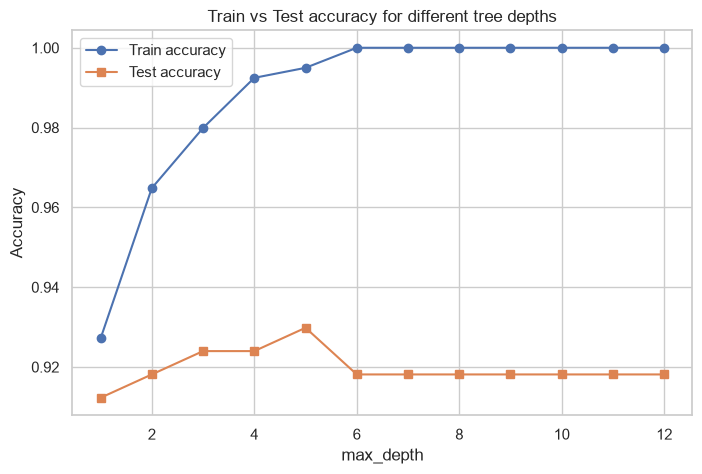

In [5]:
plt.figure(figsize=(8, 5))
plt.plot(depths, train_acc, "o-", label="Train accuracy")
plt.plot(depths, test_acc, "s-", label="Test accuracy")
plt.xlabel("max_depth")
plt.ylabel("Accuracy")
plt.title("Train vs Test accuracy for different tree depths")
plt.legend()
plt.show()

**Observation:** Train accuracy keeps increasing with depth and reaches 100%, but test accuracy stops improving after a small depth. The growing gap between the two curves shows **overfitting**.

## 4. Effect of splitting criterion

At every node, the tree picks the split that reduces impurity the most.

- **Gini impurity:** $1 - \sum p_i^2$
- **Entropy:** $-\sum p_i \log_2 p_i$

We compare both criteria for the same range of depths.

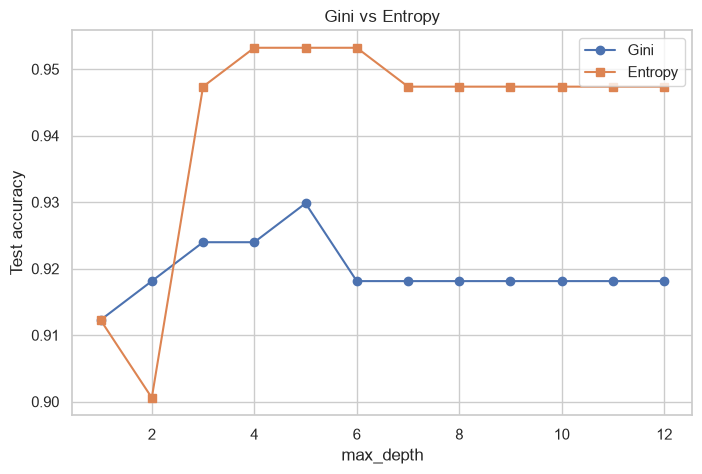

In [6]:
gini_acc, entropy_acc = [], []

for d in depths:
    g = DecisionTreeClassifier(criterion="gini", max_depth=d, random_state=42).fit(X_train, y_train)
    e = DecisionTreeClassifier(criterion="entropy", max_depth=d, random_state=42).fit(X_train, y_train)
    gini_acc.append(g.score(X_test, y_test))
    entropy_acc.append(e.score(X_test, y_test))

plt.figure(figsize=(8, 5))
plt.plot(depths, gini_acc, "o-", label="Gini")
plt.plot(depths, entropy_acc, "s-", label="Entropy")
plt.xlabel("max_depth")
plt.ylabel("Test accuracy")
plt.title("Gini vs Entropy")
plt.legend()
plt.show()

We can also show both criteria side by side as a heatmap (rows = criterion, columns = depth).

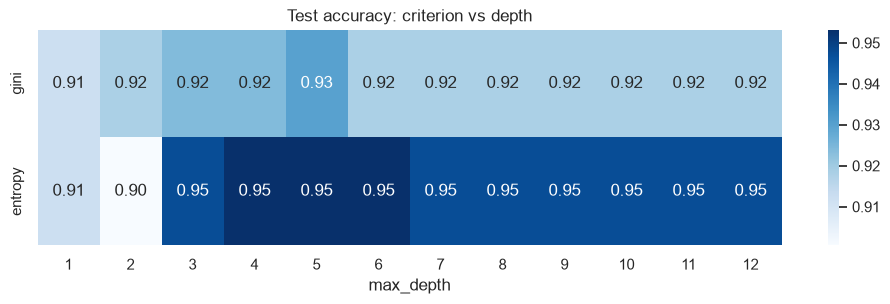

In [7]:
table = pd.DataFrame([gini_acc, entropy_acc], index=["gini", "entropy"], columns=list(depths))
plt.figure(figsize=(12, 2.8))
sns.heatmap(table, annot=True, fmt=".2f", cmap="Blues")
plt.xlabel("max_depth")
plt.title("Test accuracy: criterion vs depth")
plt.show()

**Observation:** Gini and Entropy give very similar accuracy. The choice of criterion matters much less than the choice of depth.

## 5. Visualise a decision tree
A small tree (depth 3) is easy to read. Each box shows the splitting rule, impurity, number of samples and the predicted class.

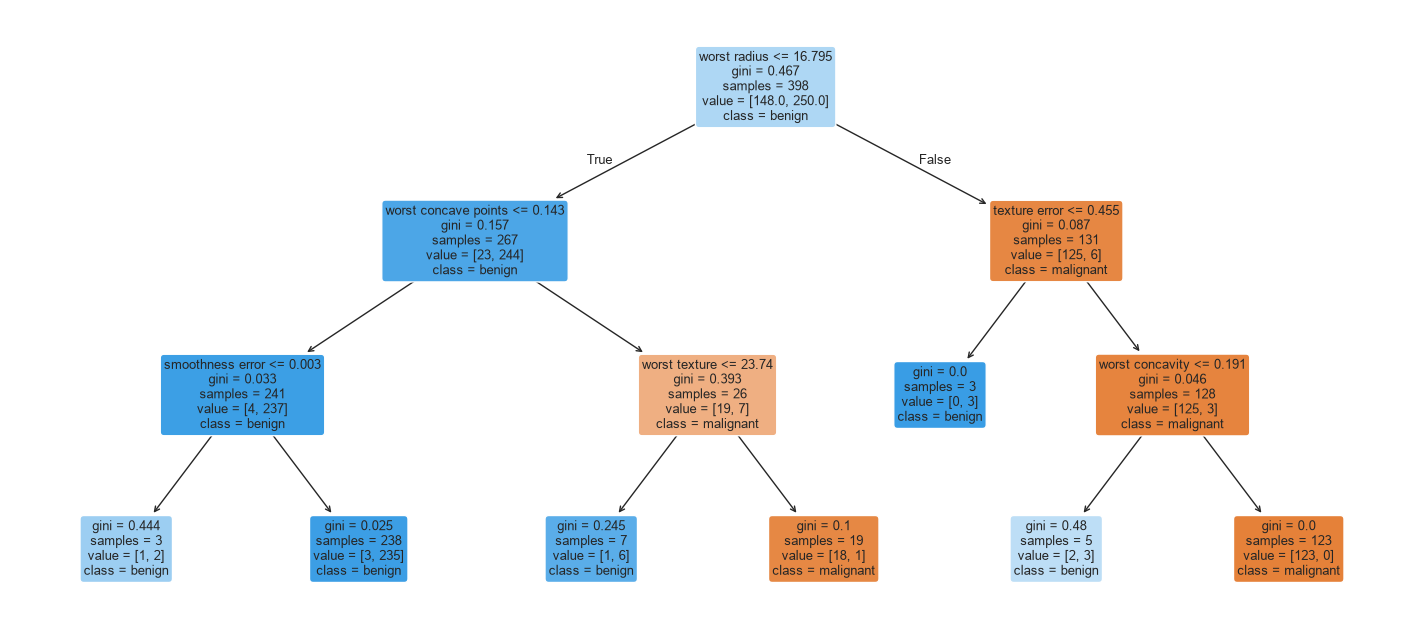

Test accuracy of this tree: 0.924


In [8]:
small_tree = DecisionTreeClassifier(max_depth=3, random_state=42).fit(X_train, y_train)

plt.figure(figsize=(18, 8))
plot_tree(small_tree, feature_names=data.feature_names,
          class_names=data.target_names, filled=True, rounded=True, fontsize=9)
plt.show()
print("Test accuracy of this tree:", round(small_tree.score(X_test, y_test), 4))

## 6. Conclusion

1. **Depth** controls model complexity. Too shallow underfits; too deep overfits.
2. A **moderate depth** gives the best balance between training and test accuracy.
3. **Gini and Entropy** perform almost the same here; Gini is slightly faster to compute.
4. Limiting tree depth is a simple way to prevent overfitting.